# Лабораторная работа №6

## Алгоритмы Дойча, Дойча — Йожи и Шора

Для алгоритма Шора используется вариант 7: \(N=35,\ a=2\). В заданиях Дойча и Дойча — Йожи используется вариант 1. Задание 5 относится к вариантам 16–30 и для варианта 7 не выполняется.


In [1]:
import math
from collections import Counter
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import QFTGate, UnitaryGate
from qiskit.quantum_info import DensityMatrix, Statevector, partial_trace
from qiskit_aer import AerSimulator
from sympy import factorint

rng = np.random.default_rng(7)
simulator = AerSimulator(method="statevector")


def run_counts(circuits, shots, seed):
    if isinstance(circuits, QuantumCircuit):
        circuits = [circuits]
    compiled = transpile(circuits, simulator, optimization_level=0)
    result = simulator.run(compiled, shots=shots, seed_simulator=seed).result()
    return [result.get_counts(i) for i in range(len(compiled))]


def basis_truth_table(oracle, n):
    values = []
    for x in range(2**n):
        query = QuantumCircuit(n + 1)
        for qubit in range(n):
            if (x >> qubit) & 1:
                query.x(qubit)
        query.compose(oracle, inplace=True)
        probabilities = Statevector.from_instruction(query).probabilities([n])
        values.append(int(np.argmax(probabilities)))
    return values


def function_type(values):
    if all(value == values[0] for value in values):
        return "постоянная"
    if sum(values) * 2 == len(values):
        return "сбалансированная"
    return "ни постоянная, ни сбалансированная"


## Задание 1. Алгоритм Дойча

### 1.1–1.2. Основная схема и состояние после оракула

В алгоритме целевой кубит подготавливается в |->. Оракул в этом состоянии действует фазой (-1)^f(x): входное значение не меняется, но суперпозиция управляющего кубита становится |+> для постоянной функции и |-> для сбалансированной. Поэтому после последнего H измеряется 0 или 1 соответственно.


In [2]:
def twobit_function(case):
    if case not in (1, 2, 3, 4):
        raise ValueError("case должен быть от 1 до 4")
    oracle = QuantumCircuit(2)
    if case in (2, 3):
        oracle.cx(0, 1)
    if case in (3, 4):
        oracle.x(1)
    return oracle


def deutsch_circuit(oracle, target_x=True, initial_h=True):
    circuit = QuantumCircuit(2, 1)
    if target_x:
        circuit.x(1)
    if initial_h:
        circuit.h(0)
    circuit.h(1)
    circuit.compose(oracle, inplace=True)
    circuit.h(0)
    circuit.measure(0, 0)
    return circuit


selected_oracle = twobit_function(1)
selected_counts = run_counts(deutsch_circuit(selected_oracle), shots=1024, seed=61)[0]
selected_truth = basis_truth_table(selected_oracle, n=1)
selected_type = function_type(selected_truth)
selected_result = max(selected_counts, key=selected_counts.get)
assert ("сбалансированная" if selected_result == "1" else "постоянная") == selected_type
print("Функция | f(0), f(1) | Измерения (shots=1024) | Тип")
print(f"1 | {selected_truth} | {selected_counts} | {selected_type}")

plus = Statevector([1 / np.sqrt(2), 1 / np.sqrt(2)])
minus = Statevector([1 / np.sqrt(2), -1 / np.sqrt(2)])
print("Оракул | тип функции | rho_0 | сравнение с теорией")
for case in range(1, 5):
    oracle = twobit_function(case)
    state_circuit = QuantumCircuit(2)
    state_circuit.h(0)
    state_circuit.x(1)
    state_circuit.h(1)
    state_circuit.compose(oracle, inplace=True)
    reduced = partial_trace(Statevector.from_instruction(state_circuit), [1])
    expected = DensityMatrix(plus) if function_type(basis_truth_table(oracle, 1)) == "постоянная" else DensityMatrix(minus)
    assert np.allclose(reduced.data, expected.data)
    print(f"{case} | {function_type(basis_truth_table(oracle, 1))} | {np.round(reduced.data, 3).tolist()} | совпадает")

print("Проверены 4 функции: редуцированные состояния совпали с теорией.")


Функция | f(0), f(1) | Измерения (shots=1024) | Тип
1 | [0, 0] | {'0': 1024} | постоянная
Оракул | тип функции | rho_0 | сравнение с теорией
1 | постоянная | [[(0.5+0j), (0.5+0j)], [(0.5+0j), (0.5+0j)]] | совпадает
2 | сбалансированная | [[(0.5+0j), (-0.5+0j)], [(-0.5+0j), (0.5+0j)]] | совпадает
3 | сбалансированная | [[(0.5+0j), (-0.5+0j)], [(-0.5+0j), (0.5+0j)]] | совпадает
4 | постоянная | [[(0.5+0j), (0.5+0j)], [(0.5+0j), (0.5+0j)]] | совпадает
Проверены 4 функции: редуцированные состояния совпали с теорией.


### 1.3–1.5. Изменённые схемы и оракул как чёрный ящик

Без X целевой кубит не готовится в |->, фазовый отклик не используется и результат может быть неверным. Без первого H управляющий кубит остаётся |0>, поэтому измерение после заключительного H равновероятно и не определяет тип функции. В п. 1.5 ответы проверяются для четырёх заданных оракулов и 100 случайных функций; схема содержит один вызов оракула.


In [3]:
def dominant_bit(counts):
    return max(counts, key=counts.get)


no_target_x = run_counts(
    [deutsch_circuit(twobit_function(i), target_x=False) for i in range(1, 5)],
    shots=1024,
    seed=62,
)
no_initial_h = run_counts(
    [deutsch_circuit(twobit_function(i), initial_h=False) for i in range(1, 5)],
    shots=1024,
    seed=63,
)
print("Оракул | f(0), f(1) | измеренный бит | ответ алгоритма | правильный ответ | совпадение")
for i, counts in enumerate(no_target_x, start=1):
    truth = basis_truth_table(twobit_function(i), 1)
    measured = dominant_bit(counts)
    answer = "сбалансированная" if measured == "1" else "постоянная"
    correct = function_type(truth)
    print(f"{i} | {truth} | {measured} | {answer} | {correct} | {answer == correct}")
print("Без первого H: измерения по оракулам")
for i, counts in enumerate(no_initial_h, start=1):
    truth = basis_truth_table(twobit_function(i), 1)
    print(f"{i} | {truth} | {counts}")


def oracle_from_values(values):
    n = int(math.log2(len(values)))
    if 2**n != len(values) or any(value not in (0, 1) for value in values):
        raise ValueError("Нужна таблица из 2^n битов")
    oracle = QuantumCircuit(n + 1)
    for x, value in enumerate(values):
        if not value:
            continue
        zeros = [q for q in range(n) if not ((x >> q) & 1)]
        for q in zeros:
            oracle.x(q)
        oracle.mcx(list(range(n)), n)
        for q in zeros:
            oracle.x(q)
    return oracle


def deutsch_decide(oracle):
    circuit = QuantumCircuit(2, 1)
    circuit.x(1)
    circuit.h([0, 1])
    oracle_gate = oracle.to_gate()
    circuit.append(oracle_gate, [0, 1])
    assert sum(item.operation.name == oracle_gate.name for item in circuit.data) == 1
    circuit.h(0)
    circuit.measure(0, 0)
    state = Statevector.from_instruction(circuit.remove_final_measurements(inplace=False))
    bit = int(np.argmax(state.probabilities([0])))
    return "сбалансированная" if bit == 1 else "постоянная"


for case in range(1, 5):
    values = basis_truth_table(twobit_function(case), 1)
    assert deutsch_decide(twobit_function(case)) == function_type(values)

for trial in range(100):
    if rng.integers(2):
        bit = int(rng.integers(2))
        values = [bit, bit]
    else:
        values = [0, 1] if rng.integers(2) else [1, 0]
    oracle = oracle_from_values(values)
    assert deutsch_decide(oracle) == function_type(values)
print("Проверки пройдены: 4 исходных оракула, 100 случайных функций; один вызов оракула.")


Оракул | f(0), f(1) | измеренный бит | ответ алгоритма | правильный ответ | совпадение
1 | [0, 0] | 0 | постоянная | постоянная | True
2 | [0, 1] | 0 | постоянная | сбалансированная | False
3 | [1, 0] | 0 | постоянная | сбалансированная | False
4 | [1, 1] | 0 | постоянная | постоянная | True
Без первого H: измерения по оракулам
1 | [0, 0] | {'1': 531, '0': 493}
2 | [0, 1] | {'1': 494, '0': 530}
3 | [1, 0] | {'0': 535, '1': 489}
4 | [1, 1] | {'1': 482, '0': 542}
Проверки пройдены: 4 исходных оракула, 100 случайных функций; один вызов оракула.


## Задание 2. Алгоритм Дойча — Йожи

### 2.1–2.2. Проверка оракулов и построение по таблице истинности


In [4]:
def dj_from_truth_table(values):
    return oracle_from_values(values)


def random_promise_values(n, balanced=None):
    size = 2**n
    if balanced is None:
        balanced = bool(rng.integers(2))
    if balanced:
        values = np.zeros(size, dtype=int)
        values[rng.choice(size, size // 2, replace=False)] = 1
        return values.tolist()
    return [int(rng.integers(2))] * size


def dj_circuit(oracle, n):
    circuit = QuantumCircuit(n + 1, n)
    circuit.x(n)
    circuit.h(range(n + 1))
    circuit.compose(oracle, inplace=True)
    circuit.h(range(n))
    circuit.measure(range(n), range(n))
    return circuit


oracle_tests = []
n = 2
for _ in range(5):
    values = random_promise_values(n)
    oracle_tests.append((n, dj_from_truth_table(values), values))

tested_counts = run_counts(
    [dj_circuit(oracle, n) for n, oracle, _ in oracle_tests],
    shots=1024,
    seed=71,
)
for (n, oracle, _), counts in zip(oracle_tests, tested_counts):
    inferred = function_type(basis_truth_table(oracle, n))
    measured = "постоянная" if counts.get("0" * n, 0) == 1024 else "сбалансированная"
    assert measured == inferred
print("Оракул | измеренная битовая строка | ответ алгоритма | истинный тип | совпадение")
for index, ((n, oracle, _), counts) in enumerate(zip(oracle_tests, tested_counts), start=1):
    bitstring = max(counts, key=counts.get)
    answer = "постоянная" if counts.get("0" * n, 0) == 1024 else "сбалансированная"
    actual = function_type(basis_truth_table(oracle, n))
    print(f"{index} | {bitstring} | {answer} | {actual} | {answer == actual}")
print(f"Проверено {len(oracle_tests)} случайных оракулов для n=2; по 1024 shots.")


checked = []
for n in (2, 3, 4):
    for balanced in (False, True):
        for _ in range(50):
            values = random_promise_values(n, balanced=balanced)
            checked.append((n, dj_from_truth_table(values), function_type(values)))
counts = run_counts([dj_circuit(oracle, n) for n, oracle, _ in checked], shots=1, seed=72)
for (n, oracle, expected), result in zip(checked, counts):
    actual = "постоянная" if result.get("0" * n, 0) else "сбалансированная"
    assert actual == expected
print(f"Проверено {len(checked)} таблиц для n=2,3,4 (по 50 каждого типа на n).")


Оракул | измеренная битовая строка | ответ алгоритма | истинный тип | совпадение
1 | 00 | постоянная | постоянная | True
2 | 00 | постоянная | постоянная | True
3 | 10 | сбалансированная | сбалансированная | True
4 | 00 | постоянная | постоянная | True
5 | 10 | сбалансированная | сбалансированная | True
Проверено 5 случайных оракулов для n=2; по 1024 shots.
Проверено 300 таблиц для n=2,3,4 (по 50 каждого типа на n).


### 2.3–2.4. Нарушение обещания, сложность и число запросов

Для произвольной таблицы значений вероятность исхода всех нулей вычисляется по формуле: P(0^n) = (2^(-n) · Σ_x (-1)^(f(x)))^2. Поэтому при нарушении обещания исход 0^n сам по себе не доказывает постоянство функции.

Квантовый алгоритм использует один запрос. Вероятностный классический алгоритм достигает ошибки не более 1% за несколько запросов, тогда как детерминированному требуется проверить больше половины входов, чтобы исключить сбалансированную функцию.


Единиц: 1; P(000) теория=0.5625, симуляция=0.5634
Единиц: 2; P(000) теория=0.2500, симуляция=0.2500
Единиц: 3; P(000) теория=0.0625, симуляция=0.0638
Монте-Карло n=3,q=3: 0.1470; по формуле: 0.1429
n | кубитов | глубина | детерм. запросы | вероятн. запросы (ошибка <= 1%) | квантовые | проверка ответа
2 | 3 | 10 | 3 | 3 | 1 | True
3 | 4 | 18 | 5 | 5 | 1 | True
4 | 5 | 1 | 9 | 6 | 1 | True
5 | 6 | 34 | 17 | 7 | 1 | True
6 | 7 | 130 | 33 | 8 | 1 | True
7 | 8 | 1 | 65 | 8 | 1 | True


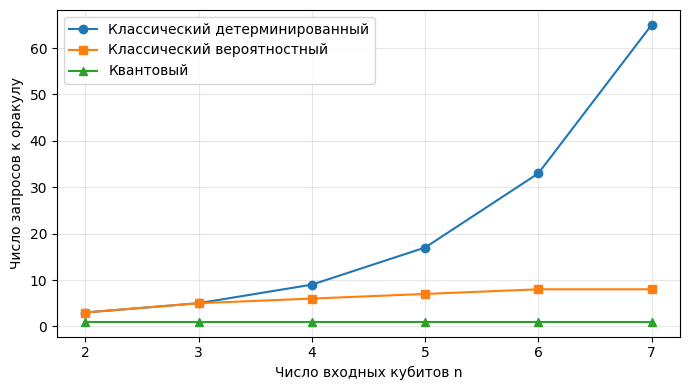

In [5]:
n = 3
non_promise_values = []
for ones in (1, 2, 3):
    values = [0] * (2**n)
    for x in range(ones):
        values[x] = 1
    non_promise_values.append(values)

non_promise_circuits = [
    dj_circuit(dj_from_truth_table(values), n) for values in non_promise_values
]
non_promise_counts = run_counts(non_promise_circuits, shots=20_000, seed=73)
for ones, values, counts in zip((1, 2, 3), non_promise_values, non_promise_counts):
    signed_sum = sum((-1) ** value for value in values)
    theoretical = (signed_sum / (2**n)) ** 2
    observed = counts.get("0" * n, 0) / 20_000
    assert abs(observed - theoretical) < 0.02
    print(f"Единиц: {ones}; P(000) теория={theoretical:.4f}, симуляция={observed:.4f}")

def classical_error(n, q):
    half = 2 ** (n - 1)
    total = 2**n
    if q > half:
        return 0.0
    return 2 * math.comb(half, q) / math.comb(total, q)


mc_trials = 20_000
mc_errors = 0
for _ in range(mc_trials):
    ones = set(rng.choice(8, 4, replace=False))
    inputs = rng.choice(8, 3, replace=False)
    observed_values = [int(x in ones) for x in inputs]
    mc_errors += len(set(observed_values)) == 1
mc_probability = mc_errors / mc_trials
exact_probability = classical_error(3, 3)
assert abs(mc_probability - exact_probability) < 0.02
print(
    f"Монте-Карло n=3,q=3: {mc_probability:.4f}; "
    f"по формуле: {exact_probability:.4f}"
)

ns = list(range(2, 8))
deterministic_queries = [2 ** (n - 1) + 1 for n in ns]
randomized_queries = []
for n in ns:
    randomized_queries.append(
        next(q for q in range(1, 2 ** (n - 1) + 2) if classical_error(n, q) <= 0.01)
    )
quantum_queries = [1] * len(ns)
print("n | кубитов | глубина | детерм. запросы | вероятн. запросы (ошибка <= 1%) | квантовые | проверка ответа")
for n in ns:
    values = random_promise_values(n)
    circuit = dj_circuit(dj_from_truth_table(values), n)
    compiled = transpile(circuit, simulator, optimization_level=1)
    counts = run_counts(circuit, shots=1024, seed=80 + n)[0]
    inferred = function_type(basis_truth_table(dj_from_truth_table(values), n))
    measured = "постоянная" if counts.get("0" * n, 0) == 1024 else "сбалансированная"
    assert measured == inferred
    print(
        n,
        compiled.num_qubits,
        compiled.depth(),
        deterministic_queries[n - 2],
        randomized_queries[n - 2],
        1,
        measured == inferred,
        sep=" | ",
    )

plt.figure(figsize=(7, 4))
plt.plot(ns, deterministic_queries, "o-", label="Классический детерминированный")
plt.plot(ns, randomized_queries, "s-", label="Классический вероятностный")
plt.plot(ns, quantum_queries, "^-", label="Квантовый")
plt.xlabel("Число входных кубитов n")
plt.ylabel("Число запросов к оракулу")
plt.xticks(ns)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()



## Задания 3–4. Алгоритм Шора для варианта 7

Для \(N=35,\ a=2\): \(\gcd(2,35)=1\), \(35=5\cdot7\), а перебор даёт порядок \(r=12\). Это составное число, поэтому у него есть нетривиальные множители, которые можно получить через НОД.

Успешным считается измерение, для которого восстановленный знаменатель r больше 1 и a^r mod N = 1. В идеальном случае доля таких измерений равна φ(r)/r: собственные фазы k/r равновероятны, а знаменатель сокращается до r при gcd(k,r)=1. При недостаточном m соседние фазы разрешаются хуже, поэтому дробь может не восстановить r.

Для выбранного основания a=2 условия факторизации выполняются, поэтому дополнительное основание не требуется. При p=φ(r)/r вероятность не получить успех за 1024 независимых измерения равна (1-p)^1024; повторные измерения практичнее, чем увеличение регистра.


In [6]:
def order_mod(a, N):
    value = 1
    for r in range(1, N + 1):
        value = (value * a) % N
        if value == 1:
            return r
    raise ValueError("Порядок не найден")


def euler_phi(value):
    return sum(math.gcd(k, value) == 1 for k in range(1, value + 1))


def modular_multiplier(b, N, n):
    if math.gcd(b, N) != 1:
        raise ValueError("Множитель должен быть взаимно прост с N")
    dimension = 2**n
    matrix = np.zeros((dimension, dimension), dtype=complex)
    for x in range(N):
        matrix[(b * x) % N, x] = 1
    for x in range(N, dimension):
        matrix[x, x] = 1
    for x in range(N):
        image = int(np.argmax(matrix[:, x]))
        assert image == (b * x) % N
    return UnitaryGate(matrix, label=f"M_{b}")


compiled_shor = {}


def compiled_shor_circuit(N, a, m):
    key = (N, a, m)
    if key in compiled_shor:
        return compiled_shor[key]
    n = math.ceil(math.log2(N))
    circuit = QuantumCircuit(m + n, m)
    circuit.x(m)
    for k in range(m):
        circuit.h(k)
        b = pow(a, 2**k, N)
        if b != 1:
            circuit.append(
                modular_multiplier(b, N, n).control(),
                [k] + list(range(m, m + n)),
            )
    circuit.append(QFTGate(m).inverse(), list(range(m)))
    circuit.measure(range(m), range(m))
    compiled = transpile(circuit, simulator, optimization_level=0)
    compiled_shor[key] = compiled
    return compiled


def shor_counts(N, a, m, shots, seed):
    compiled = compiled_shor_circuit(N, a, m)
    return simulator.run(compiled, shots=shots, seed_simulator=seed).result().get_counts()


def valid_order_candidates(counts, N, a, m):
    candidates = Counter()
    for bitstring, count in counts.items():
        y = int(bitstring, 2)
        r = Fraction(y, 2**m).limit_denominator(N).denominator
        if r > 1 and pow(a, r, N) == 1:
            candidates[r] += count
    return candidates


def success_fraction(counts, N, a, m):
    candidates = valid_order_candidates(counts, N, a, m)
    return sum(candidates.values()) / sum(counts.values()), candidates


N, a = 35, 2
n = math.ceil(math.log2(N))
assert math.gcd(a, N) == 1
assert factorint(N) == {5: 1, 7: 1}
r = order_mod(a, N)
phi_ratio = euler_phi(r) / r
m = 2 * n
print(f"N={N}, a={a}, n={n}, m={m}, r={r}, phi(r)/r={phi_ratio:.4f}")

counts_2000 = shor_counts(N, a, m, shots=2000, seed=91)
p_hat, candidate_orders = success_fraction(counts_2000, N, a, m)
assert candidate_orders
print(f"Успешные измерения: {sum(candidate_orders.values())}/2000 = {p_hat:.4f}")


found_r = candidate_orders.most_common(1)[0][0]
x = pow(a, found_r // 2, N)
d1 = math.gcd(x - 1, N)
d2 = math.gcd(x + 1, N)
assert found_r % 2 == 0 and x not in (1, N - 1)
factors = sorted((d1, d2))
assert factors[0] * factors[1] == N and factors[0] > 1 and factors[1] > 1
print(f"r={found_r}: a^(r/2) mod N={x}; gcd(x-1,N)={d1}; gcd(x+1,N)={d2}")
print("Нетривиальные множители:", factors)

precision_rows = []
for control_qubits in (n + 1, 2 * n - 1, 2 * n):
    if control_qubits == m:
        counts = counts_2000
    else:
        counts = shor_counts(N, a, control_qubits, shots=2000, seed=100 + control_qubits)
    observed, candidate_orders = success_fraction(counts, N, a, control_qubits)
    precision_rows.append((control_qubits, observed, phi_ratio))
print("m | доля успешных измерений | phi(r)/r")
for row in precision_rows:
    print(f"{row[0]} | {row[1]:.4f} | {row[2]:.4f}")
standard_error = math.sqrt(phi_ratio * (1 - phi_ratio) / 2000)
matching_m = [
    control_qubits
    for control_qubits, observed, _ in precision_rows
    if abs(observed - phi_ratio) <= standard_error
]
print(
    f"Стандартная ошибка доли при 2000 shots: {standard_error:.4f}; "
    f"минимальное проверенное m в пределах ошибки: {min(matching_m)}."
)

run_fractions = []
for seed in range(201, 206):
    counts = shor_counts(N, a, m, shots=1024, seed=seed)
    fraction, _ = success_fraction(counts, N, a, m)
    run_fractions.append(fraction)
mean_fraction = float(np.mean(run_fractions))
std_fraction = float(np.std(run_fractions, ddof=1))
repeats_99 = math.ceil(math.log(0.01) / math.log(1 - phi_ratio))
print("Пять независимых запусков по 1024 shots:", [round(v, 4) for v in run_fractions])
print(f"Средняя доля={mean_fraction:.4f}, стандартное отклонение={std_fraction:.4f}")
print(f"Для вероятности успеха не менее 99% нужно T={repeats_99} независимых измерений.")



N=35, a=2, n=6, m=12, r=12, phi(r)/r=0.3333
Успешные измерения: 669/2000 = 0.3345
r=12: a^(r/2) mod N=29; gcd(x-1,N)=7; gcd(x+1,N)=5
Нетривиальные множители: [5, 7]
m | доля успешных измерений | phi(r)/r
7 | 0.0000 | 0.3333
11 | 0.3250 | 0.3333
12 | 0.3345 | 0.3333
Стандартная ошибка доли при 2000 shots: 0.0105; минимальное проверенное m в пределах ошибки: 11.
Пять независимых запусков по 1024 shots: [0.332, 0.3145, 0.3398, 0.3262, 0.332]
Средняя доля=0.3289, стандартное отклонение=0.0094
Для вероятности успеха не менее 99% нужно T=12 независимых измерений.


## Задание 6. Функция поиска множителей

Внутри `shor_factor` множители получаются только из порядка и НОД; готовые средства факторизации используются только в проверке результата. Для больших N измерения моделируются по распределению фаз из задания 5.

Для простого N=1009 нет нетривиальных множителей: при чётном порядке a^(r/2) равно -1 по модулю N, поэтому НОД даёт только 1 и N. При нечётном r целого показателя r/2 нет. Для 2048-битного N оценка числа кубитов равна 3·2048=6144.


In [7]:
def phase_window(theta, m, window=300):
    scale = 2**m
    center = scale * theta
    left = max(0, math.floor(center) - window)
    right = min(scale - 1, math.ceil(center) + window)
    ys = np.arange(left, right + 1)
    delta = center - ys
    denominator = scale * np.sin(np.pi * delta / scale)
    probabilities = np.empty(len(ys), dtype=float)
    zero = np.isclose(denominator, 0.0, atol=1e-14)
    probabilities[zero] = 1.0
    probabilities[~zero] = (
        np.sin(np.pi * delta[~zero]) / denominator[~zero]
    ) ** 2
    probabilities /= probabilities.sum()
    return ys, probabilities


def emulated_shor_counts(N, a, m, shots, seed):
    order = order_mod(a, N)
    generator = np.random.default_rng(seed)
    counts = Counter()
    for _ in range(shots):
        k = int(generator.integers(order))
        ys, probabilities = phase_window(k / order, m)
        y = int(generator.choice(ys, p=probabilities))
        counts[f"{y:0{m}b}"] += 1
    return dict(counts)


def factors_from_order(N, a, r):
    if r <= 1 or r % 2:
        return None
    x = pow(a, r // 2, N)
    if x in (1, N - 1):
        return None
    p = math.gcd(x - 1, N)
    q = math.gcd(x + 1, N)
    if 1 < p < N and 1 < q < N:
        return tuple(sorted((p, q)))
    return None


def shor_factor(N, bases, shots=2000, seed=301):
    n = math.ceil(math.log2(N))
    m = 2 * n
    for attempt, base in enumerate(bases, start=1):
        if math.gcd(base, N) != 1:
            continue
        if N < 64:
            counts = shor_counts(N, base, m, shots, seed + attempt)
        else:
            counts = emulated_shor_counts(N, base, m, shots, seed + attempt)
        candidates = valid_order_candidates(counts, N, base, m)
        for candidate, _ in candidates.most_common():
            factors = factors_from_order(N, base, candidate)
            if factors is not None:
                return factors[0], factors[1], base, attempt
    return None


result = shor_factor(N=35, bases=[2], shots=2000, seed=400)
assert result is not None
p, q, used_base, attempts = result
assert p * q == 35 and 1 < p < 35 and 1 < q < 35
assert {p: 1, q: 1} == factorint(35)
assert used_base == 2 and attempts == 1
print(f"Результат shor_factor: p={p}, q={q}, основание={used_base}, попыток={attempts}")
print("Проверка с sympy.factorint прошла.")

prime = 1009
assert all(
    factors_from_order(prime, base, order_mod(base, prime)) is None
    for base in (2, 3, 5)
)
print(f"Оценка числа кубитов для 2048-битного N: {3 * 2048}")


Результат shor_factor: p=5, q=7, основание=2, попыток=1
Проверка с sympy.factorint прошла.
Оценка числа кубитов для 2048-битного N: 6144
